<h1 align='center' style='color:green'>Credit Risk Modeling</h1>

In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

pd.set_option("display.float_format", lambda x: "{:.2f}".format(x))
np.set_printoptions(suppress=True)

### Load and Explore the Data

Loading customer, loan, and bureau data to inspect their structure before combining them into a single dataset.

In [2]:
df_customers = pd.read_csv("dataset/customers.csv")
df_loans = pd.read_csv("dataset/loans.csv")
df_bureau = pd.read_csv("dataset/bureau_data.csv")

In [3]:
df_customers.shape, df_loans.shape, df_bureau.shape

((50000, 12), (50000, 15), (50000, 8))

In [4]:
df_customers.head(2)

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,state,zipcode
0,C00001,44,M,Married,Self-Employed,2586000,3,Owned,27,Delhi,Delhi,110001
1,C00002,38,M,Married,Salaried,1206000,3,Owned,4,Chennai,Tamil Nadu,600001


In [5]:
df_loans.head(2)

,loan_id,cust_id,loan_purpose,loan_type,sanction_amount,loan_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,disbursal_date,installment_start_dt,default
0,L00001,C00001,Auto,Secured,3004000,2467000,49340.00,444060,1973600,33,1630408,873386,2019-07-24,2019-08-10,False
1,L00002,C00002,Home,Secured,4161000,3883000,77660.00,698940,3106400,30,709309,464100,2019-07-24,2019-08-15,False


In [6]:
df_bureau.head(2)

,cust_id,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio
0,C00001,1,1,42,0,0,3,7
1,C00002,3,1,96,12,60,5,4


### Merging the Datasets

In [7]:
df = pd.merge(df_customers, df_loans, on="cust_id")
df.head(3)

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,...,loan_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,disbursal_date,installment_start_dt,default
0,C00001,44,M,Married,Self-Employed,2586000,3,Owned,27,Delhi,...,2467000,49340.00,444060,1973600,33,1630408,873386,2019-07-24,2019-08-10,False
1,C00002,38,M,Married,Salaried,1206000,3,Owned,4,Chennai,...,3883000,77660.00,698940,3106400,30,709309,464100,2019-07-24,2019-08-15,False
2,C00003,46,F,Married,Self-Employed,2878000,3,Owned,24,Kolkata,...,2170000,43400.00,390600,1736000,21,1562399,1476042,2019-07-24,2019-08-21,False


In [8]:
df = pd.merge(df, df_bureau, on='cust_id')
df.head(3)

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,...,disbursal_date,installment_start_dt,default,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio
0,C00001,44,M,Married,Self-Employed,2586000,3,Owned,27,Delhi,...,2019-07-24,2019-08-10,False,1,1,42,0,0,3,7
1,C00002,38,M,Married,Salaried,1206000,3,Owned,4,Chennai,...,2019-07-24,2019-08-15,False,3,1,96,12,60,5,4
2,C00003,46,F,Married,Self-Employed,2878000,3,Owned,24,Kolkata,...,2019-07-24,2019-08-21,False,2,1,82,24,147,6,58


These three datasets are merged using `cust_id` to create a single dataset containing customer, loan, and credit bureau information.

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 33 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   cust_id                      50000 non-null  str    
 1   age                          50000 non-null  int64  
 2   gender                       50000 non-null  str    
 3   marital_status               50000 non-null  str    
 4   employment_status            50000 non-null  str    
 5   income                       50000 non-null  int64  
 6   number_of_dependants         50000 non-null  int64  
 7   residence_type               49938 non-null  str    
 8   years_at_current_address     50000 non-null  int64  
 9   city                         50000 non-null  str    
 10  state                        50000 non-null  str    
 11  zipcode                      50000 non-null  int64  
 12  loan_id                      50000 non-null  str    
 13  loan_purpose               

### Define the Target Variable

In [10]:
df["default"] = df["default"].astype(int)
df.default.value_counts()

default
0    45703
1     4297
Name: count, dtype: int64

The target variable is `default`, where 0 represents no default and 1 represents default. The target distribution is imbalanced, with substantially fewer default cases. We will address class imbalance during model development.

### Train-Test Split

Splitting  the data before performing EDA and feature engineering to prevent information from the test set from influencing modeling decisions.

In [11]:
X = df.drop("default", axis = 1)
y = df["default"]

X_train, X_test, y_train, y_test = train_test_split(X, y, stratify = y, test_size = 0.25, random_state = 42)

df_train = pd.concat([X_train, y_train], axis = 1)
df_test = pd.concat([X_test, y_test], axis = 1)

df_train.head(2)

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,...,disbursal_date,installment_start_dt,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,default
12746,C12747,59,M,Married,Self-Employed,11327000,3,Owned,30,Hyderabad,...,2020-10-31,2020-11-11,4,2,152,20,118,4,36,0
32495,C32496,44,F,Single,Salaried,715000,0,Owned,27,Mumbai,...,2022-10-22,2022-10-27,3,1,160,10,62,5,5,0


In [12]:
df_train.shape, df_test.shape

((37500, 33), (12500, 33))

<h3 align="center" style="color:green">Data Cleaning</h3>

#### Handling Missing Values

In [13]:
df_train.isna().sum()

cust_id                         0
age                             0
gender                          0
marital_status                  0
employment_status               0
income                          0
number_of_dependants            0
residence_type                 47
years_at_current_address        0
city                            0
state                           0
zipcode                         0
loan_id                         0
loan_purpose                    0
loan_type                       0
sanction_amount                 0
loan_amount                     0
processing_fee                  0
gst                             0
net_disbursement                0
loan_tenure_months              0
principal_outstanding           0
bank_balance_at_application     0
disbursal_date                  0
installment_start_dt            0
number_of_open_accounts         0
number_of_closed_accounts       0
total_loan_months               0
delinquent_months               0
total_dpd     

In [14]:
df_train["residence_type"].unique()

<ArrowStringArray>
['Owned', 'Mortgage', 'Rented', nan]
Length: 4, dtype: str

In [15]:
mode_residence = df_train["residence_type"].mode()[0]
mode_residence

'Owned'

In [16]:
df_train["residence_type"] = df_train["residence_type"].fillna(mode_residence)
df_test["residence_type"] = df_test["residence_type"].fillna(mode_residence)

df_train["residence_type"].unique(), df_test["residence_type"].unique()

(<ArrowStringArray>
 ['Owned', 'Mortgage', 'Rented']
 Length: 3, dtype: str,
 <ArrowStringArray>
 ['Owned', 'Mortgage', 'Rented']
 Length: 3, dtype: str)

In [17]:
df_train.duplicated().sum()

np.int64(0)

In [18]:
df_train.columns

Index(['cust_id', 'age', 'gender', 'marital_status', 'employment_status',
       'income', 'number_of_dependants', 'residence_type',
       'years_at_current_address', 'city', 'state', 'zipcode', 'loan_id',
       'loan_purpose', 'loan_type', 'sanction_amount', 'loan_amount',
       'processing_fee', 'gst', 'net_disbursement', 'loan_tenure_months',
       'principal_outstanding', 'bank_balance_at_application',
       'disbursal_date', 'installment_start_dt', 'number_of_open_accounts',
       'number_of_closed_accounts', 'total_loan_months', 'delinquent_months',
       'total_dpd', 'enquiry_count', 'credit_utilization_ratio', 'default'],
      dtype='str')

#### Identifying Numerical and Categorical Features

In [19]:
columns_continuous = ['age', 'income', 'number_of_dependants', 'years_at_current_address', 
                      'sanction_amount', 'loan_amount', 'processing_fee', 'gst', 'net_disbursement', 
                      'loan_tenure_months','principal_outstanding', 'bank_balance_at_application',
                      'number_of_open_accounts','number_of_closed_accounts', 'total_loan_months', 'delinquent_months',
                       'total_dpd', 'enquiry_count', 'credit_utilization_ratio']

columns_categorical = ['gender', 'marital_status', 'employment_status', 'residence_type', 'city', 
                       'state', 'zipcode', 'loan_purpose', 'loan_type', 'default']

#### Analyzing Numerical Features for Outliers

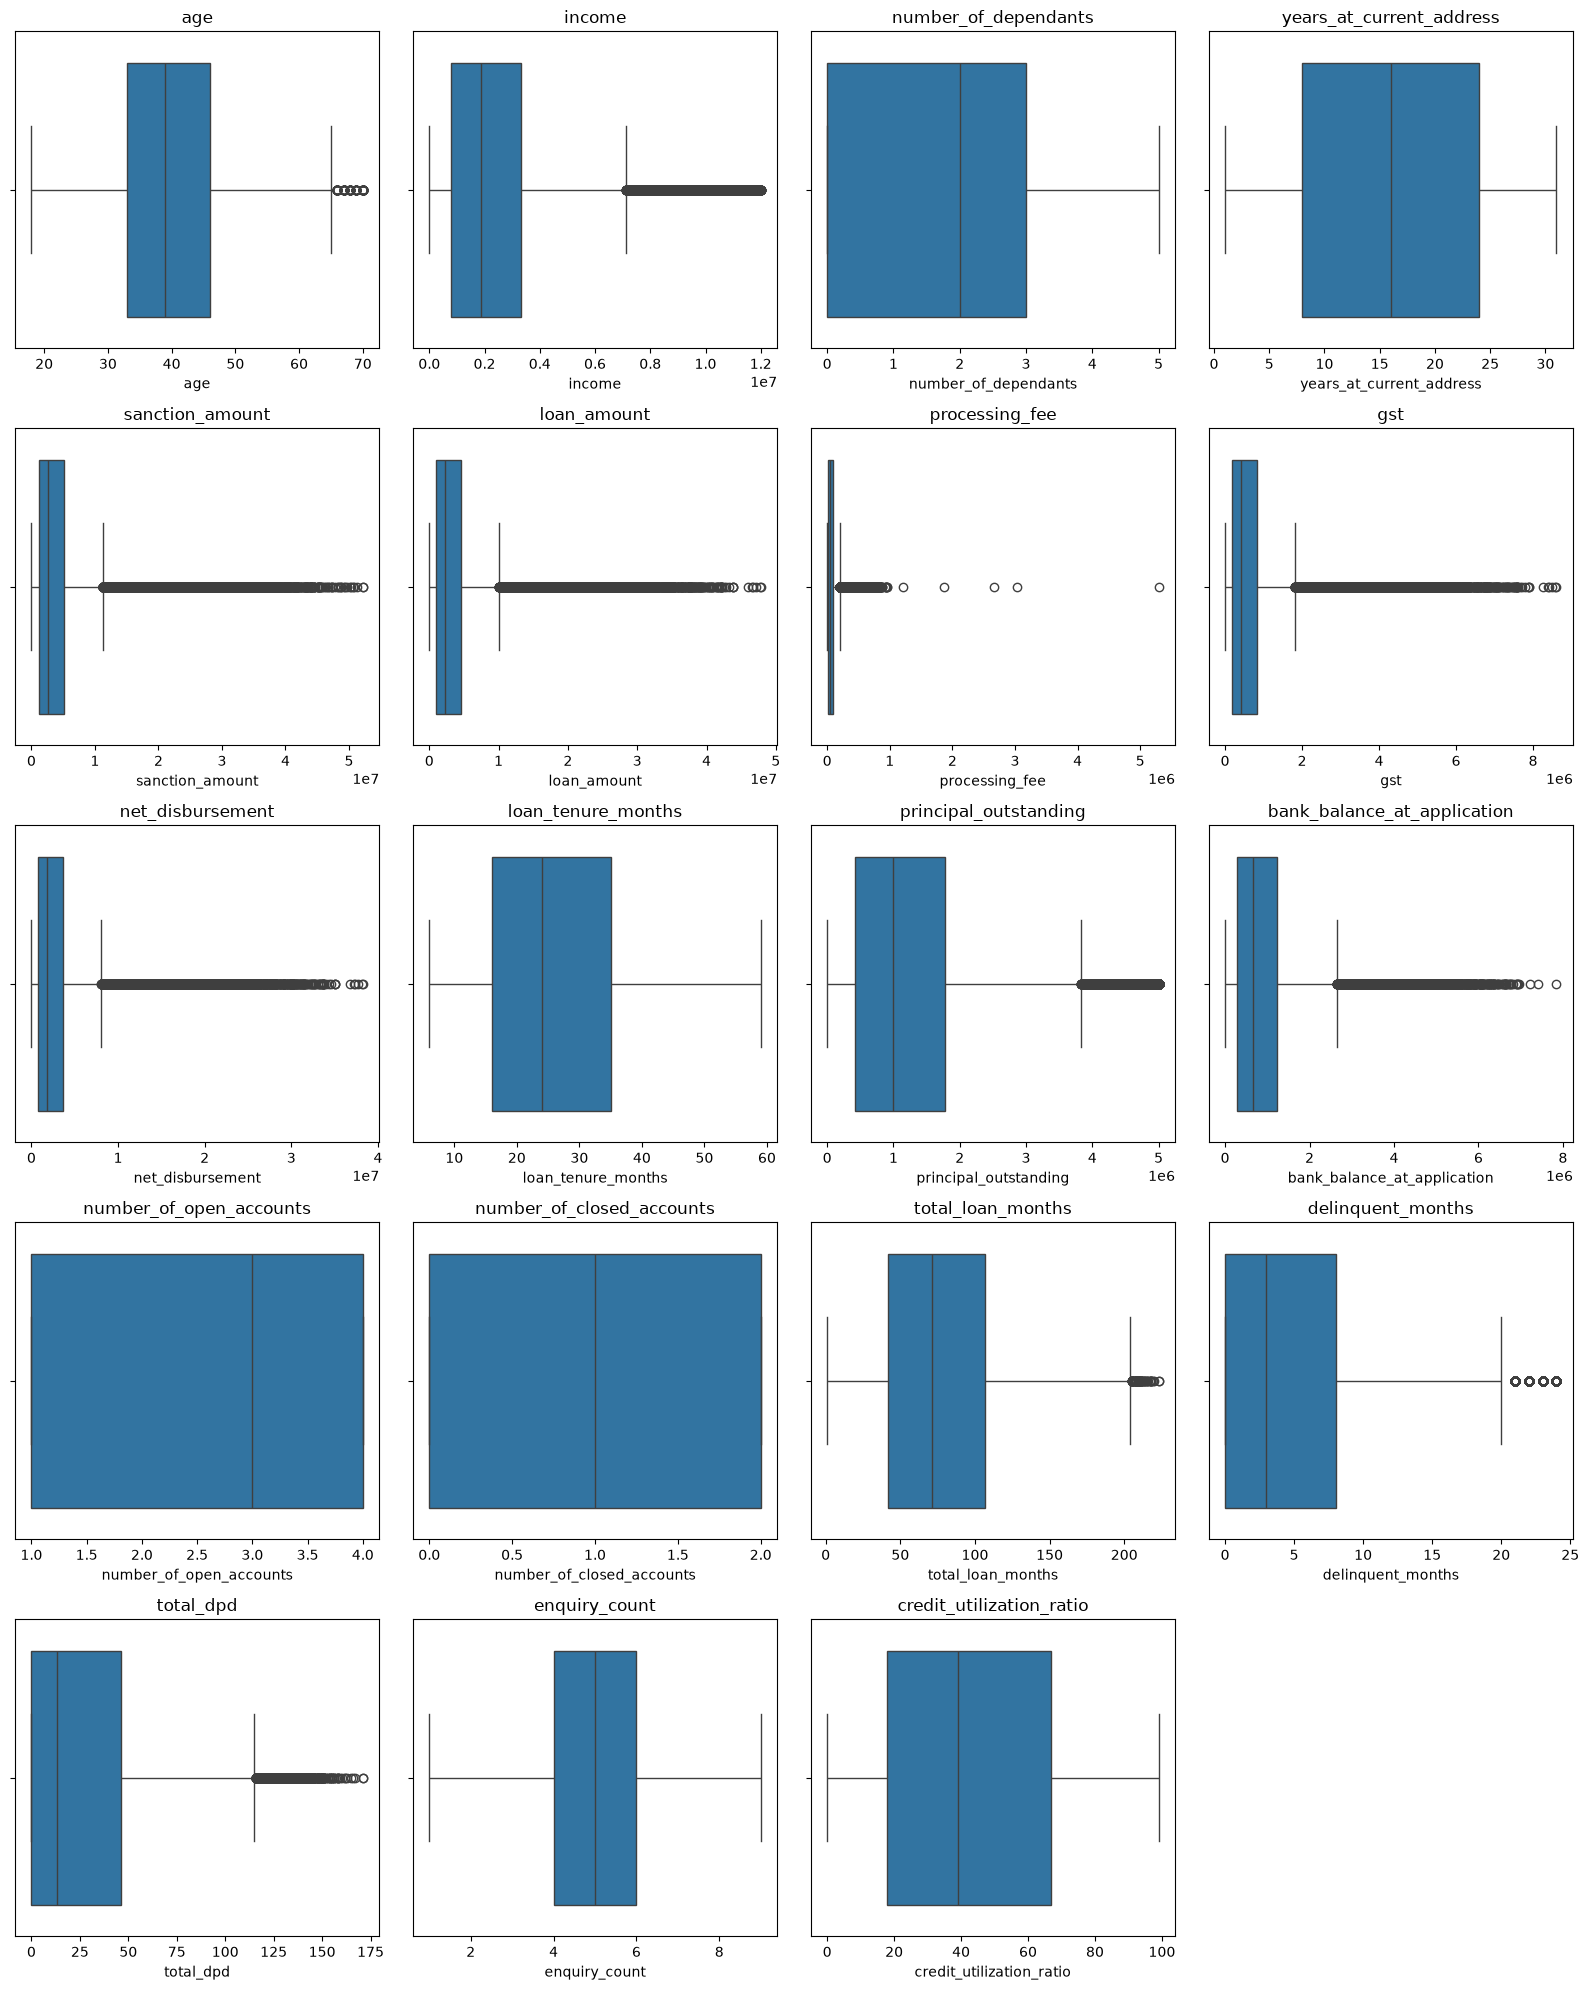

In [20]:
n_cols = 4
n_rows = (len(columns_continuous) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4 * n_rows))
axes = axes.flatten()

for i, column in enumerate(columns_continuous):
    sns.boxplot(x=df_train[column], ax=axes[i])
    axes[i].set_title(column)

# Hide unused plots
for i in range(len(columns_continuous), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()

#### Distribution of Numerical Features

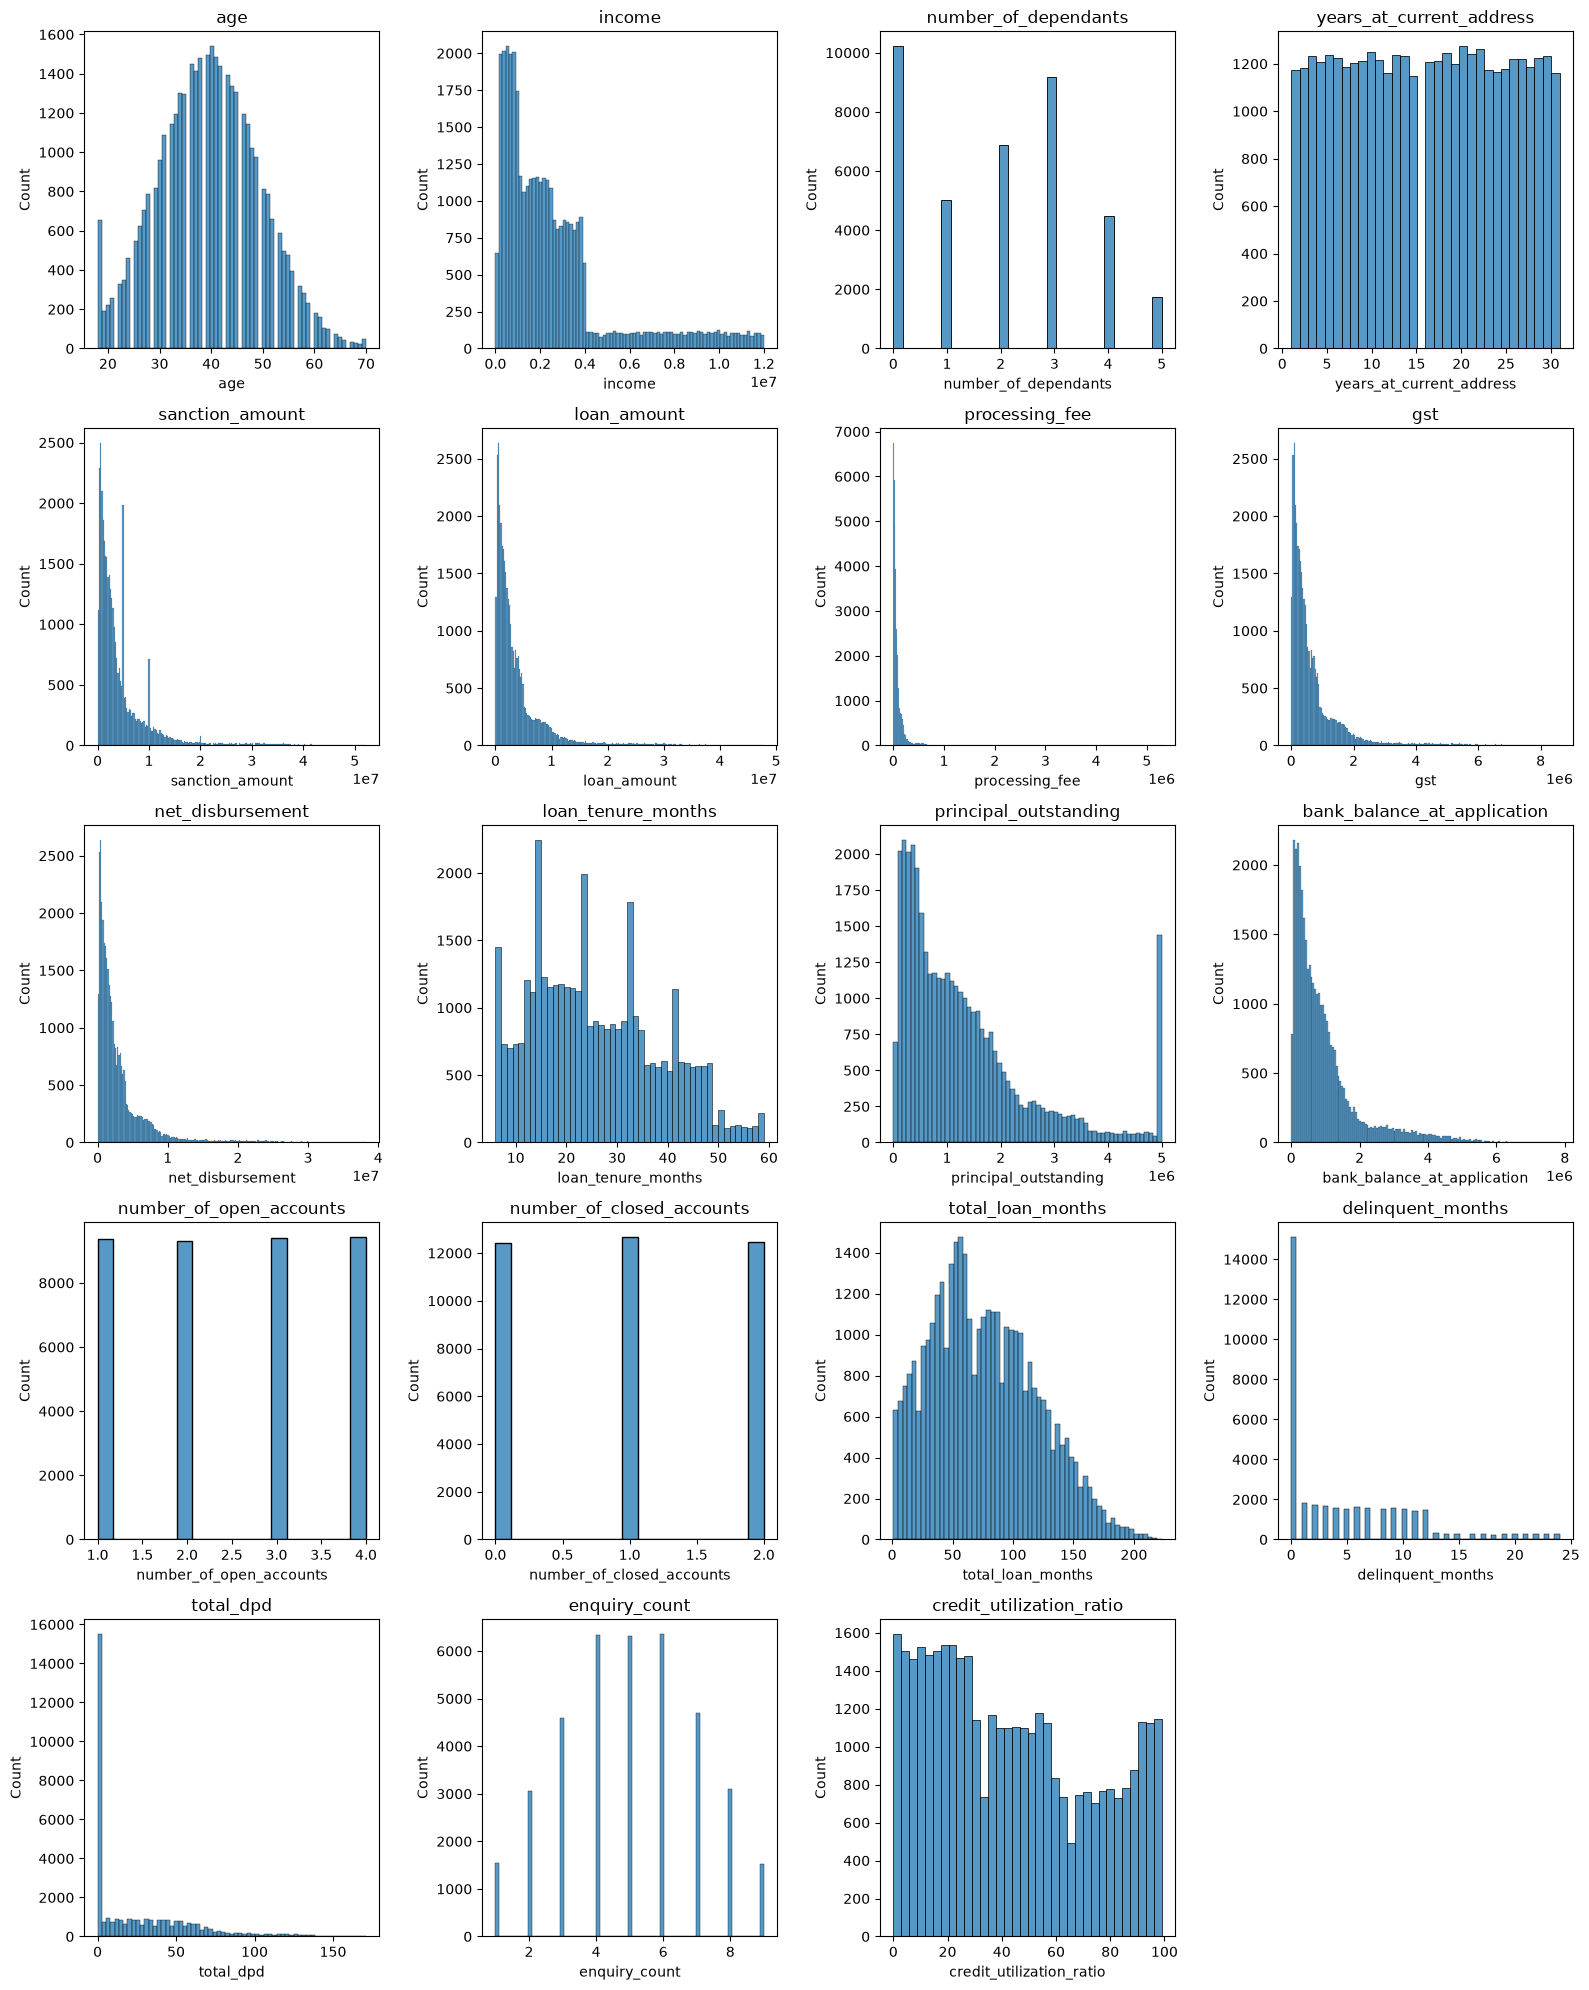

In [21]:
n_cols = 4
n_rows = (len(columns_continuous) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4 * n_rows))
axes = axes.flatten()

for i, column in enumerate(columns_continuous):
    sns.histplot(x=df_train[column], ax=axes[i])
    axes[i].set_title(column)

# Hide unused plots
for i in range(len(columns_continuous), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()

#### Applying Business Rule to Processing Fee

In [22]:
df_train["processing_fee"].describe()

count     37500.00
mean      80290.68
std      113128.14
min           0.00
25%       19220.00
50%       44600.00
75%       92420.00
max     5293543.52
Name: processing_fee, dtype: float64

In [23]:
df_train[(df_train["processing_fee"]/df_train["loan_amount"])>0.03][["loan_amount", "processing_fee"]]

,loan_amount,processing_fee
23981,2234000,2669791.02
28174,966000,1214492.67
47089,1738000,1858964.77
29305,2616000,3036378.01
9898,3626000,5293543.52


In [24]:
df_train_1 = df_train[(df_train["processing_fee"]/df_train["loan_amount"])<0.03].copy()
df_train_1.shape

(37488, 33)

In [25]:
df_test = df_test[(df_test["processing_fee"]/df_test["loan_amount"])<0.03].copy()
df_test.shape

(12497, 33)

#### Analyzing Categorical Features

In [26]:
columns_categorical

['gender',
 'marital_status',
 'employment_status',
 'residence_type',
 'city',
 'state',
 'zipcode',
 'loan_purpose',
 'loan_type',
 'default']

In [27]:
for col in columns_categorical:
    print(f"Column: {col} {df_train_1[col].unique()}")
    print("")

Column: gender <ArrowStringArray>
['M', 'F']
Length: 2, dtype: str

Column: marital_status <ArrowStringArray>
['Married', 'Single']
Length: 2, dtype: str

Column: employment_status <ArrowStringArray>
['Self-Employed', 'Salaried']
Length: 2, dtype: str

Column: residence_type <ArrowStringArray>
['Owned', 'Mortgage', 'Rented']
Length: 3, dtype: str

Column: city <ArrowStringArray>
['Hyderabad',    'Mumbai',   'Chennai', 'Bangalore',      'Pune',   'Kolkata',
 'Ahmedabad',     'Delhi',   'Lucknow',    'Jaipur']
Length: 10, dtype: str

Column: state <ArrowStringArray>
[    'Telangana',   'Maharashtra',    'Tamil Nadu',     'Karnataka',
   'West Bengal',       'Gujarat',         'Delhi', 'Uttar Pradesh',
     'Rajasthan']
Length: 9, dtype: str

Column: zipcode [500001 400001 600001 560001 411001 700001 380001 110001 226001 302001]

Column: loan_purpose <ArrowStringArray>
['Home', 'Education', 'Personal', 'Auto', 'Personaal']
Length: 5, dtype: str

Column: loan_type <ArrowStringArray>
['Secu

#### Fixing Data Entry Errors

In [28]:
df_train_1["loan_purpose"] = df_train_1["loan_purpose"].replace('Personaal', "Personal")
df_test["loan_purpose"] = df_test["loan_purpose"].replace('Personaal', "Personal")

<h3 style="color:green" align="center">Exploratory Data Analysis</h3>

In [29]:
columns_continuous

['age',
 'income',
 'number_of_dependants',
 'years_at_current_address',
 'sanction_amount',
 'loan_amount',
 'processing_fee',
 'gst',
 'net_disbursement',
 'loan_tenure_months',
 'principal_outstanding',
 'bank_balance_at_application',
 'number_of_open_accounts',
 'number_of_closed_accounts',
 'total_loan_months',
 'delinquent_months',
 'total_dpd',
 'enquiry_count',
 'credit_utilization_ratio']

#### Age vs Default

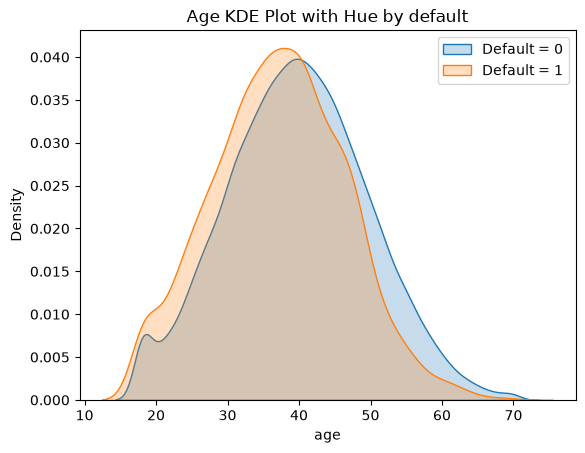

In [30]:
sns.kdeplot(df_train_1[df_train_1["default"] == 0]["age"], fill = True, label = "Default = 0")
sns.kdeplot(df_train_1[df_train_1["default"] == 1]["age"], fill = True, label = "Default = 1")
plt.title(f"Age KDE Plot with Hue by default")
plt.legend()
plt.show()

**Insights**

The defaulted group is slightly shifted toward lower ages, indicating that younger customers are more likely to default on their loans.

#### Numerical Feature Distributions

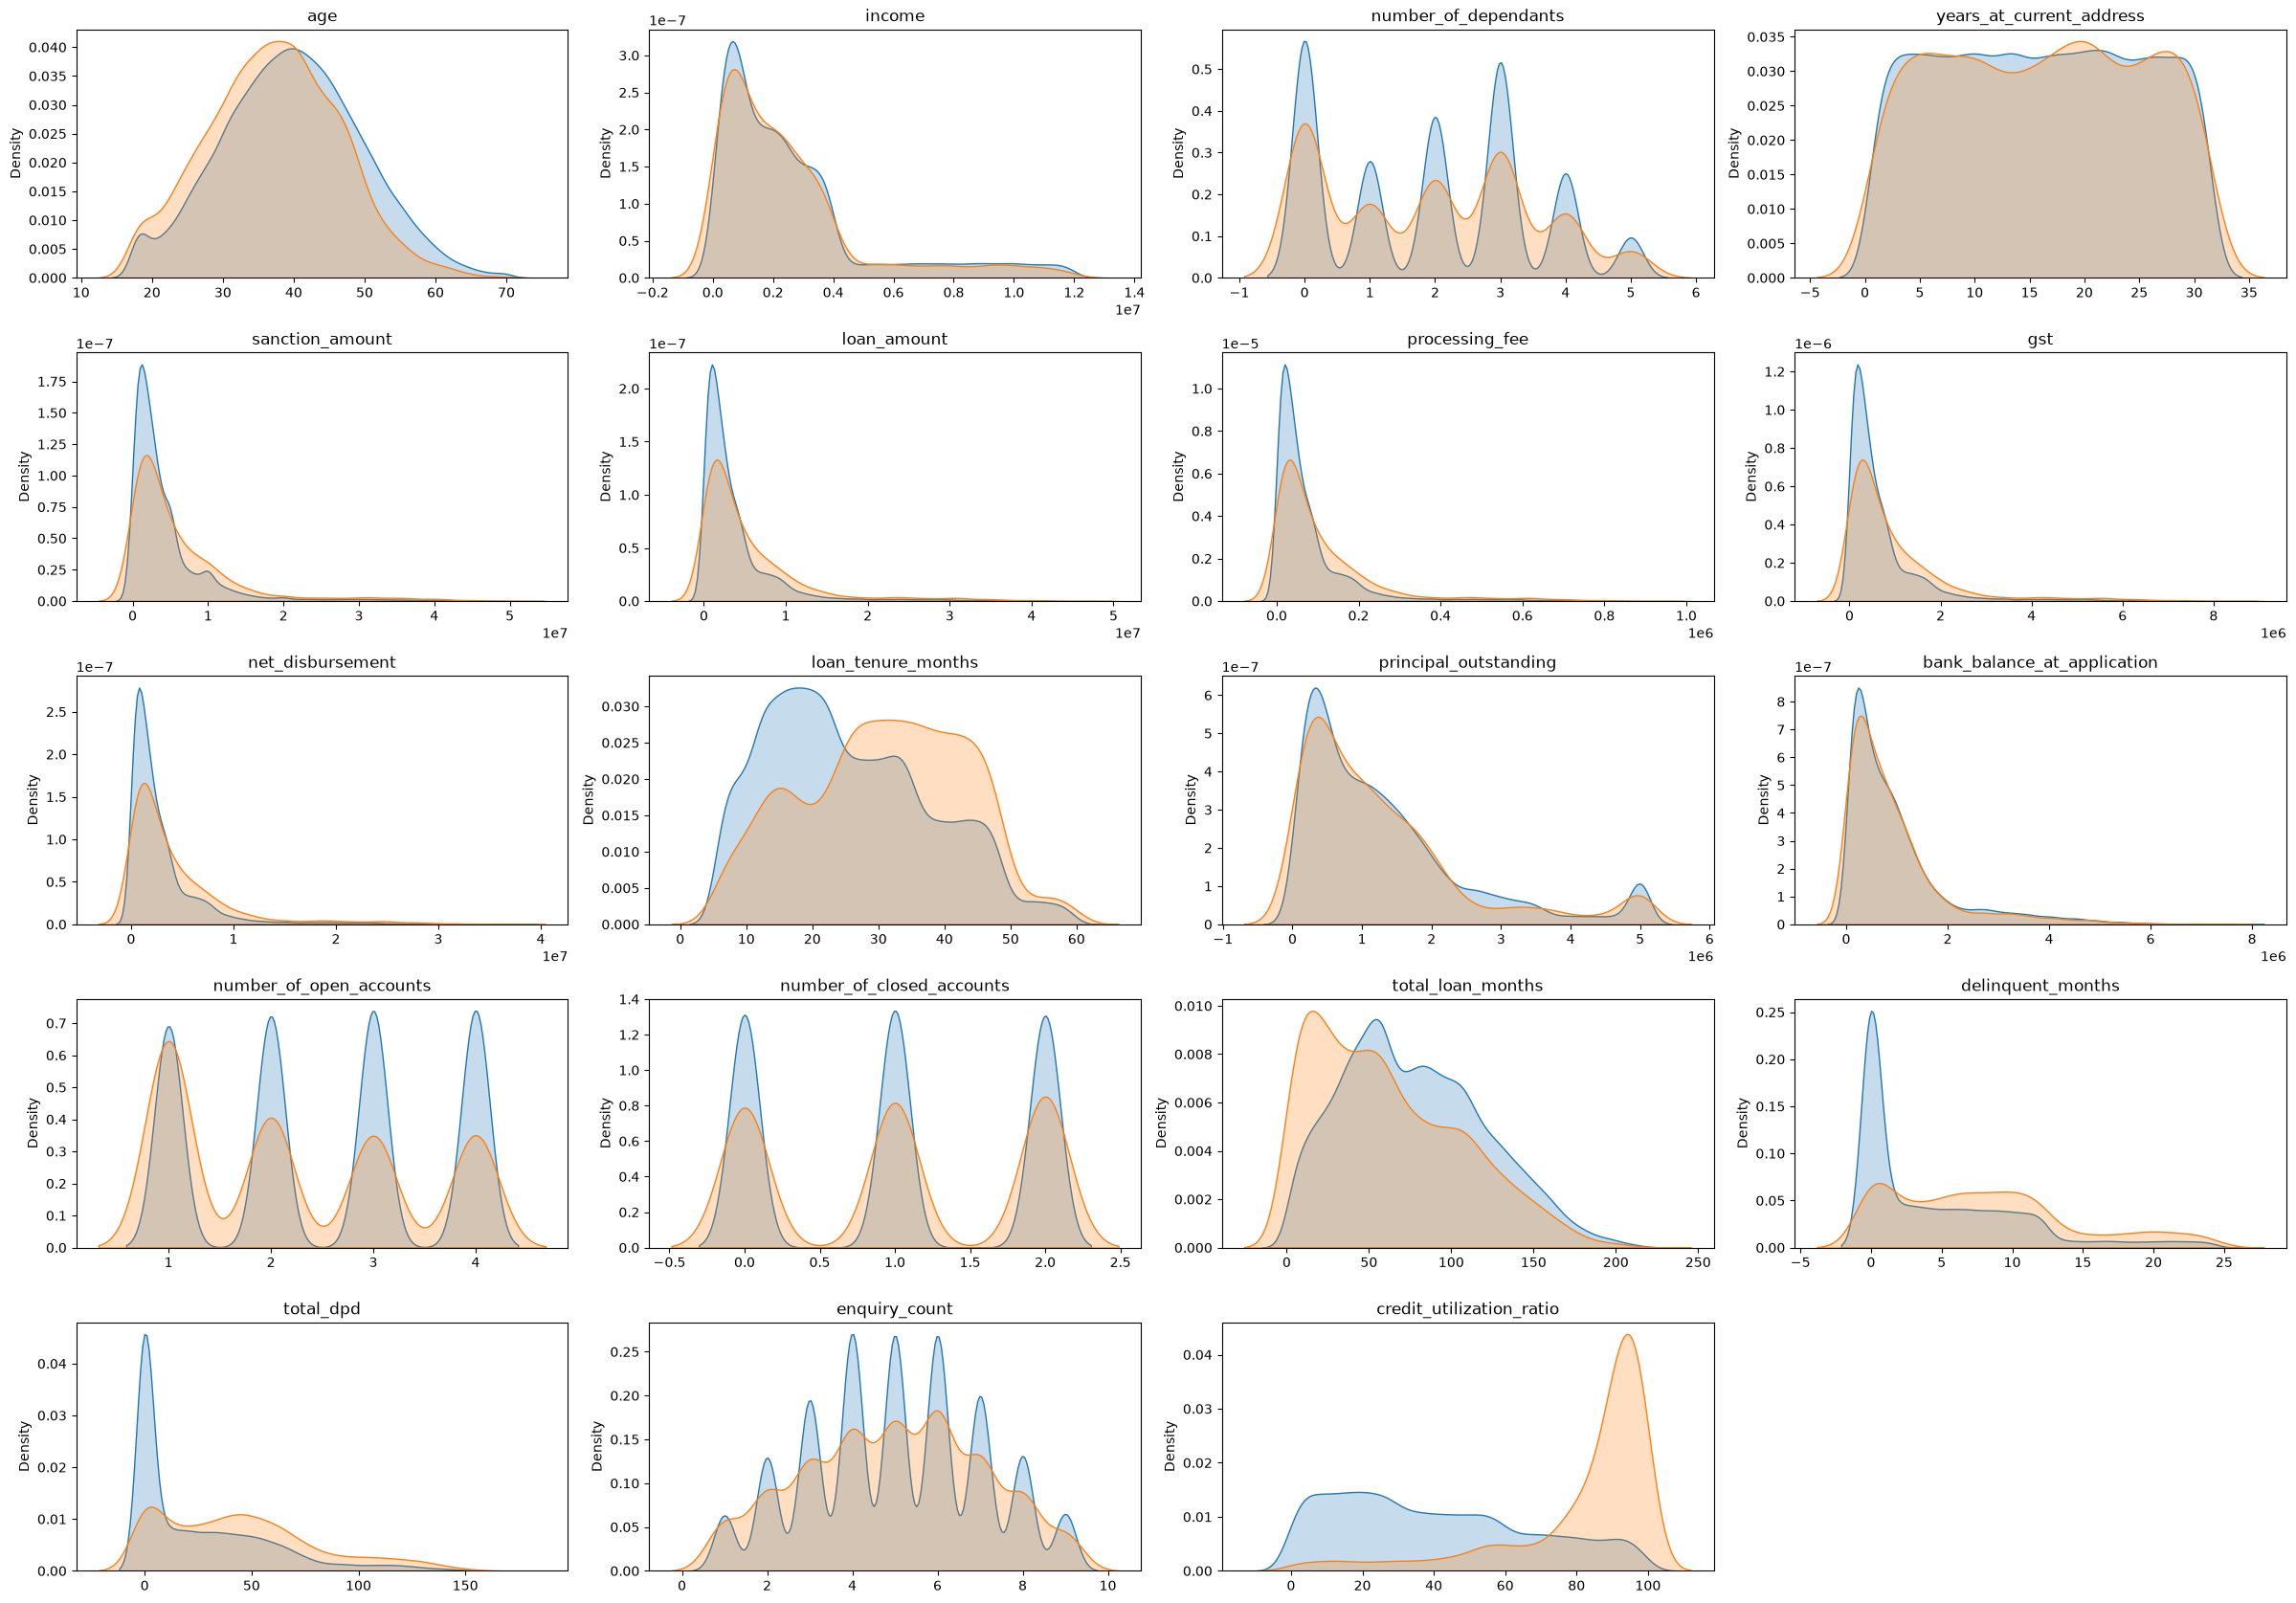

In [37]:
plt.figure(figsize=(24, 20))

for i, col in enumerate(columns_continuous):
    plt.subplot(6, 4, i+1)
    sns.kdeplot(df_train_1[col][df_train_1['default']==0], fill=True, label='default=0')
    sns.kdeplot(df_train_1[col][df_train_1['default']==1], fill=True, label='default=1')
    plt.title(col)        
    plt.xlabel('')
    
plt.tight_layout()
plt.show()

**Insights**

- Higher values of `loan_tenure_months`, `delinquent_months`, `total_dpd`, and `credit_utilization_ratio` are linked to a higher chance of default.
- The other numerical features do not show any clear pattern between default and non-default customers.
- `loan_amount` and `income` do not show a strong pattern individually. We will combine them into a `loan_to_income` (LTI) ratio and explore it later.

<h3 style="color:green" align="center">Feature Engineering</h3>

#### Generating Loan to Income (LTI) Ratio

In [38]:
df_train_1[["loan_amount", "income"]].head(3)

,loan_amount,income
12746,23442000,11327000
32495,1149000,715000
43675,11296000,3195000


In [39]:
df_train_1["loan_to_income"] = round(df_train_1["loan_amount"]/df_train_1["income"], 2)
df_test['loan_to_income'] = round(df_test['loan_amount'] / df_test['income'], 2)

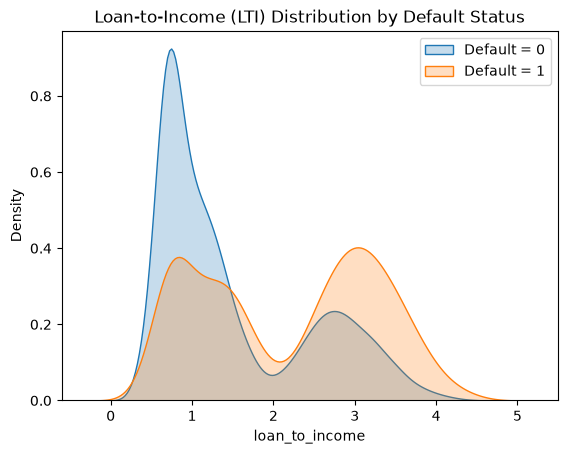

In [42]:
sns.kdeplot(df_train_1[df_train_1["default"] == 0]["loan_to_income"], fill = True, label = "Default = 0")
sns.kdeplot(df_train_1[df_train_1["default"] == 1]["loan_to_income"], fill = True, label = "Default = 1")
plt.title(f"Loan-to-Income (LTI) Distribution by Default Status")
plt.legend()
plt.show()

**Insights**

- Most non-default customers have lower `loan_to_income` (LTI) values.
- Defaulted customers are more common at higher LTI values, suggesting that a higher LTI may indicate a higher risk of default.

#### Generating Delinquency Ratio

In [43]:
df_train_1[["delinquent_months", "total_loan_months"]]

,delinquent_months,total_loan_months
12746,20,152
32495,10,160
43675,12,54
9040,0,76
13077,0,60
...,...,...
28515,0,40
5558,14,52
45236,11,130
49228,0,88


In [44]:
df_train_1["delinquent_ratio"] = (df_train_1["delinquent_months"]*100/df_train_1["total_loan_months"]).round(1)
df_test["delinquent_ratio"] = (df_test["delinquent_months"]*100/df_test["total_loan_months"]).round(1)


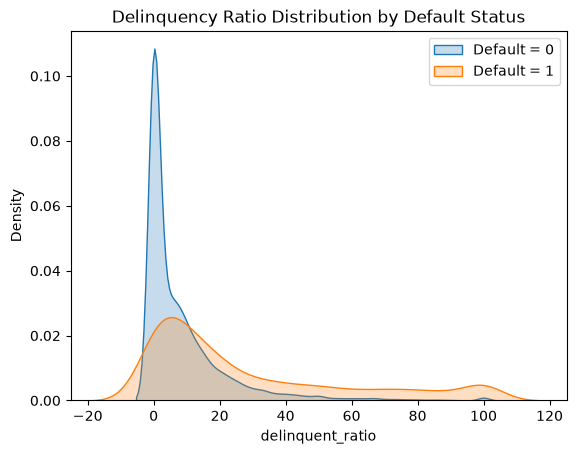

In [46]:
sns.kdeplot(df_train_1[df_train_1["default"] == 0]["delinquent_ratio"], fill = True, label = "Default = 0")
sns.kdeplot(df_train_1[df_train_1["default"] == 1]["delinquent_ratio"], fill = True, label = "Default = 1")
plt.title(f"Delinquency Ratio Distribution by Default Status")
plt.legend()
plt.show()

**Insights**

- Most non-default customers have lower delinquency ratios.
- Defaulted customers are more common at higher delinquency ratios, suggesting that a higher delinquency ratio may be linked to a higher risk of default.

#### Generating Average DPD Per Delinquency

In [47]:
df_train_1["avg_dpd_per_delinquency"] = np.where(
    df_train_1["delinquent_months"] != 0,
    (df_train_1["total_dpd"]/df_train_1["delinquent_months"]).round(1),
    0
)

df_test['avg_dpd_per_delinquency'] = np.where(
    df_test['delinquent_months'] != 0,
    (df_test['total_dpd'] / df_test['delinquent_months']).round(1),
    0
)

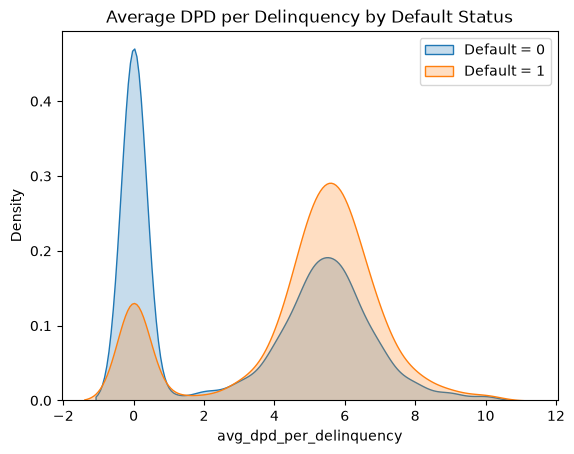

In [48]:
sns.kdeplot(df_train_1[df_train_1["default"] == 0]["avg_dpd_per_delinquency"], fill = True, label = "Default = 0")
sns.kdeplot(df_train_1[df_train_1["default"] == 1]["avg_dpd_per_delinquency"], fill = True, label = "Default = 1")
plt.title(f"Average DPD per Delinquency by Default Status")
plt.legend()
plt.show()

**Insights**

- Defaulted customers are more common at higher values of `avg_dpd_per_delinquency`.
- This suggests that customers with higher average days past due may have a higher risk of default.

### Feature Removal

In [49]:
df_train_1.columns

Index(['cust_id', 'age', 'gender', 'marital_status', 'employment_status',
       'income', 'number_of_dependants', 'residence_type',
       'years_at_current_address', 'city', 'state', 'zipcode', 'loan_id',
       'loan_purpose', 'loan_type', 'sanction_amount', 'loan_amount',
       'processing_fee', 'gst', 'net_disbursement', 'loan_tenure_months',
       'principal_outstanding', 'bank_balance_at_application',
       'disbursal_date', 'installment_start_dt', 'number_of_open_accounts',
       'number_of_closed_accounts', 'total_loan_months', 'delinquent_months',
       'total_dpd', 'enquiry_count', 'credit_utilization_ratio', 'default',
       'loan_to_income', 'delinquent_ratio', 'avg_dpd_per_delinquency'],
      dtype='str')

In [50]:
df_train_2 = df_train_1.drop(["cust_id", "loan_id"], axis = 1)
df_test = df_test.drop(['cust_id', 'loan_id'],axis="columns")

In [51]:
df_train_3 = df_train_2.drop(['disbursal_date', 'installment_start_dt', 'loan_amount', 'income', 
                              'total_loan_months', 'delinquent_months', 'total_dpd'], axis="columns")
df_test = df_test.drop(['disbursal_date', 'installment_start_dt', 'loan_amount', 'income', 
                              'total_loan_months', 'delinquent_months', 'total_dpd'], axis="columns")
df_train_3.columns

Index(['age', 'gender', 'marital_status', 'employment_status',
       'number_of_dependants', 'residence_type', 'years_at_current_address',
       'city', 'state', 'zipcode', 'loan_purpose', 'loan_type',
       'sanction_amount', 'processing_fee', 'gst', 'net_disbursement',
       'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'number_of_open_accounts',
       'number_of_closed_accounts', 'enquiry_count',
       'credit_utilization_ratio', 'default', 'loan_to_income',
       'delinquent_ratio', 'avg_dpd_per_delinquency'],
      dtype='str')

In [52]:
df_train_3.shape, df_test.shape

((37488, 27), (12497, 27))

In [53]:
df_train_3.select_dtypes(["int64", "float64"]).columns

Index(['age', 'number_of_dependants', 'years_at_current_address', 'zipcode',
       'sanction_amount', 'processing_fee', 'gst', 'net_disbursement',
       'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'number_of_open_accounts',
       'number_of_closed_accounts', 'enquiry_count',
       'credit_utilization_ratio', 'default', 'loan_to_income',
       'delinquent_ratio', 'avg_dpd_per_delinquency'],
      dtype='str')

### Multicollinearity Analysis with VIF

In [54]:
X_train = df_train_3.drop("default", axis = 1)
y_train = df_train_3["default"]

from sklearn.preprocessing import MinMaxScaler

cols_to_scale = X_train.select_dtypes(["int64", "float64"]).columns

scaler = MinMaxScaler()
X_train[cols_to_scale] = scaler.fit_transform(X_train[cols_to_scale])
X_train.describe()

,age,number_of_dependants,years_at_current_address,zipcode,sanction_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,number_of_open_accounts,number_of_closed_accounts,enquiry_count,credit_utilization_ratio,loan_to_income,delinquent_ratio,avg_dpd_per_delinquency
count,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00
mean,0.41,0.39,0.50,0.52,0.09,0.08,0.08,0.08,0.38,0.26,0.12,0.50,0.50,0.50,0.44,0.29,0.10,0.33
std,0.19,0.31,0.30,0.29,0.12,0.11,0.11,0.11,0.23,0.24,0.13,0.37,0.41,0.25,0.30,0.23,0.17,0.29
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.29,0.00,0.23,0.33,0.02,0.02,0.02,0.02,0.19,0.08,0.03,0.00,0.00,0.38,0.18,0.11,0.00,0.00
50%,0.40,0.40,0.50,0.49,0.05,0.05,0.05,0.05,0.34,0.19,0.08,0.67,0.50,0.50,0.39,0.20,0.04,0.43
75%,0.54,0.60,0.77,0.76,0.10,0.10,0.10,0.10,0.55,0.35,0.16,1.00,1.00,0.62,0.68,0.51,0.13,0.57
max,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00


#### Same transformation on test set

In [55]:
X_test = df_test.drop("default", axis = 1)
y_test = df_test["default"]

X_test[cols_to_scale] = scaler.transform(X_test[cols_to_scale])
X_test.describe()

,age,number_of_dependants,years_at_current_address,zipcode,sanction_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,number_of_open_accounts,number_of_closed_accounts,enquiry_count,credit_utilization_ratio,loan_to_income,delinquent_ratio,avg_dpd_per_delinquency
count,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00
mean,0.42,0.38,0.50,0.53,0.09,0.08,0.08,0.08,0.38,0.26,0.12,0.50,0.50,0.50,0.44,0.29,0.11,0.33
std,0.19,0.31,0.30,0.29,0.12,0.11,0.11,0.11,0.23,0.25,0.13,0.37,0.41,0.25,0.30,0.23,0.17,0.29
min,0.00,0.00,0.00,0.00,-0.00,-0.00,-0.00,-0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.29,0.00,0.23,0.33,0.02,0.02,0.02,0.02,0.19,0.08,0.03,0.00,0.00,0.38,0.18,0.11,0.00,0.00
50%,0.42,0.40,0.50,0.51,0.05,0.05,0.05,0.05,0.34,0.20,0.08,0.33,0.50,0.50,0.39,0.20,0.04,0.44
75%,0.54,0.60,0.77,0.76,0.10,0.09,0.09,0.09,0.55,0.36,0.16,0.67,1.00,0.62,0.68,0.50,0.13,0.58
max,1.00,1.00,1.00,1.00,0.98,0.96,0.96,0.96,1.00,1.00,0.94,1.00,1.00,1.00,1.00,1.00,1.00,1.00


In [56]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

def calculate_vif(data):
    vif_df = pd.DataFrame()
    vif_df["Column"] = data.columns
    vif_df["VIF"] = [variance_inflation_factor(data.values,i) for i in range(data.shape[1])]
    return vif_df

In [57]:
calculate_vif(X_train[cols_to_scale])

C:\Users\Muhammad Arif\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


,Column,VIF
0,age,5.70
1,number_of_dependants,2.73
2,years_at_current_address,3.42
3,zipcode,3.80
4,sanction_amount,101.09
5,processing_fee,inf
6,gst,inf
7,net_disbursement,inf
8,loan_tenure_months,6.18
9,principal_outstanding,16.33


In [58]:
features_to_drop_vif = ['sanction_amount', 'processing_fee', 'gst', 'net_disbursement','principal_outstanding']

X_train_1 = X_train.drop(features_to_drop_vif, axis = 1)
numeric_columns = X_train_1.select_dtypes(["int64", "float64"]).columns
numeric_columns

Index(['age', 'number_of_dependants', 'years_at_current_address', 'zipcode',
       'loan_tenure_months', 'bank_balance_at_application',
       'number_of_open_accounts', 'number_of_closed_accounts', 'enquiry_count',
       'credit_utilization_ratio', 'loan_to_income', 'delinquent_ratio',
       'avg_dpd_per_delinquency'],
      dtype='str')

In [59]:
vif_df = calculate_vif(X_train_1[numeric_columns])
vif_df

,Column,VIF
0,age,5.43
1,number_of_dependants,2.73
2,years_at_current_address,3.40
3,zipcode,3.78
4,loan_tenure_months,6.02
5,bank_balance_at_application,1.80
6,number_of_open_accounts,4.35
7,number_of_closed_accounts,2.37
8,enquiry_count,6.38
9,credit_utilization_ratio,2.92


#### Correlation Analysis

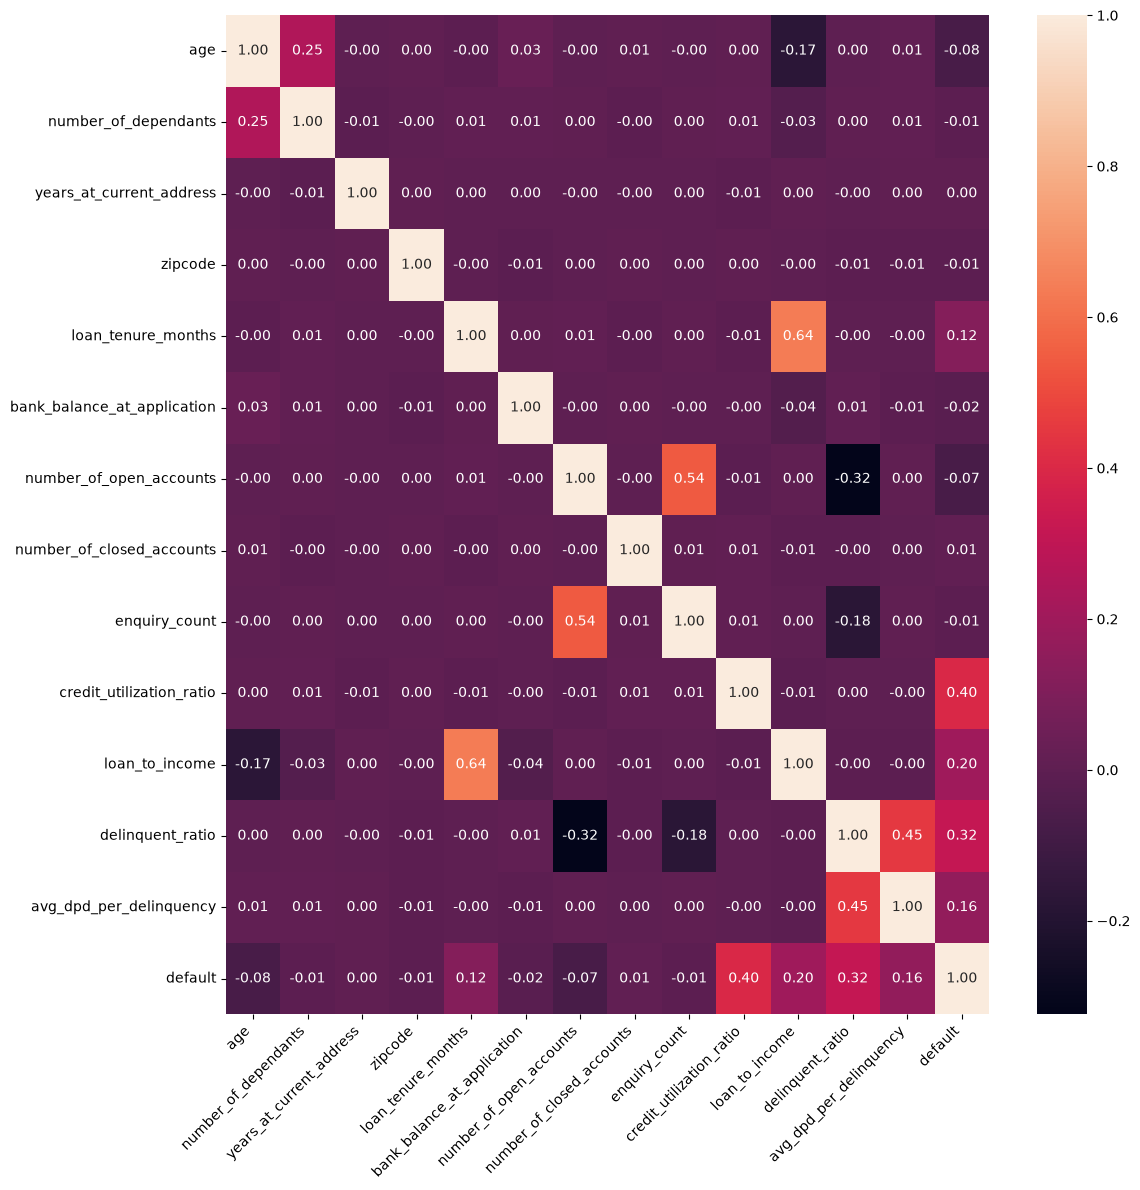

In [61]:
plt.figure(figsize=(12,12))
cm = df_train_3[numeric_columns.append(pd.Index(['default']))].corr()
sns.heatmap(cm, annot=True, fmt='0.2f')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

#### Weight of Evidence (WOE) and Information Value (IV)

In [62]:
def calculate_woe_iv(df, feature, target):
    grouped = df.groupby(feature)[target].agg(["count", "sum"])
    grouped = grouped.rename(columns={"count": "total", "sum": "good"})
    grouped["bad"] = grouped["total"] - grouped["good"]

    total_good = grouped["good"].sum()
    total_bad = grouped["bad"].sum()


    grouped["good_pct"] = grouped["good"]/total_good
    grouped["bad_pct"] = grouped["bad"]/total_bad
    grouped["woe"] = np.log(grouped["good_pct"]/grouped["bad_pct"])
    grouped["iv"] = (grouped["good_pct"] - grouped["bad_pct"])*grouped["woe"]

    grouped['woe'] = grouped['woe'].replace([np.inf, -np.inf], 0)
    grouped['iv'] = grouped['iv'].replace([np.inf, -np.inf], 0)
    total_iv = grouped["iv"].sum()
    
    return grouped, total_iv
grouped, total_iv = calculate_woe_iv(pd.concat([X_train_1, y_train], axis = 1), "loan_purpose", "default")

In [63]:
grouped

,total,good,bad,good_pct,bad_pct,woe,iv
loan_purpose,,,,,,,
Auto,7447,327,7120,0.10,0.21,-0.72,0.08
Education,5620,559,5061,0.17,0.15,0.16,0.00
Home,11304,1734,9570,0.54,0.28,0.66,0.17
Personal,13117,603,12514,0.19,0.37,-0.67,0.12


WOE and IV are used to measure the relationship between each feature and the target variable. Numerical features are first divided into 10 bins before calculating IV.

In [64]:
iv_values = {}

for feature in X_train_1.columns:
    if X_train_1[feature].dtype == "str":
        _, iv = calculate_woe_iv(pd.concat([X_train_1, y_train], axis = 1), feature, "default")

    else:
        X_binned = pd.cut(X_train_1[feature], bins = 10, labels = False)
        _, iv = calculate_woe_iv(pd.concat([X_binned, y_train], axis = 1), feature, "default")

    iv_values[feature] = iv

iv_values

{'age': np.float64(0.0890689462679479),
 'gender': np.float64(0.00047449502170914947),
 'marital_status': np.float64(0.001129766845390142),
 'employment_status': np.float64(0.003953046301722585),
 'number_of_dependants': np.float64(0.0019380899135053508),
 'residence_type': np.float64(0.246745268718145),
 'years_at_current_address': np.float64(0.0020800513608156363),
 'city': np.float64(0.0019059578709781529),
 'state': np.float64(0.0019005589806779287),
 'zipcode': np.float64(0.0016677413243392572),
 'loan_purpose': np.float64(0.3691197842282755),
 'loan_type': np.float64(0.16319324904149224),
 'loan_tenure_months': np.float64(0.21893515090196278),
 'bank_balance_at_application': np.float64(0.0063187993277516365),
 'number_of_open_accounts': np.float64(0.08463134083005877),
 'number_of_closed_accounts': np.float64(0.0011964272592421567),
 'enquiry_count': np.float64(0.007864214085342608),
 'credit_utilization_ratio': np.float64(2.352965568168245),
 'loan_to_income': np.float64(0.47641

#### Select Features Based on IV

In [65]:
pd.set_option("display.float_format", lambda x: "{:.3f}".format(x))


iv_df = pd.DataFrame(list(iv_values.items()), columns = ["Feature", "IV"])
iv_df = iv_df.sort_values(by="IV", ascending = False)
iv_df

,Feature,IV
17,credit_utilization_ratio,2.353
19,delinquent_ratio,0.717
18,loan_to_income,0.476
20,avg_dpd_per_delinquency,0.402
10,loan_purpose,0.369
5,residence_type,0.247
12,loan_tenure_months,0.219
11,loan_type,0.163
0,age,0.089
14,number_of_open_accounts,0.085


In [66]:
selected_features_iv = [feature for feature, iv in iv_values.items() if iv > 0.02]
selected_features_iv

['age',
 'residence_type',
 'loan_purpose',
 'loan_type',
 'loan_tenure_months',
 'number_of_open_accounts',
 'credit_utilization_ratio',
 'loan_to_income',
 'delinquent_ratio',
 'avg_dpd_per_delinquency']

#### Feature Encoding

In [67]:
X_train_reduced = X_train_1[selected_features_iv]
X_test_reduced = X_test[selected_features_iv]

X_train_reduced.head(2)

,age,residence_type,loan_purpose,loan_type,loan_tenure_months,number_of_open_accounts,credit_utilization_ratio,loan_to_income,delinquent_ratio,avg_dpd_per_delinquency
12746,0.788,Owned,Home,Secured,0.415,1.000,0.364,0.415,0.132,0.590
32495,0.500,Owned,Education,Secured,0.830,0.667,0.051,0.307,0.062,0.620


In [68]:
X_train_encoded = pd.get_dummies(X_train_reduced, drop_first=True)
X_train_encoded.head(3)

,age,loan_tenure_months,number_of_open_accounts,credit_utilization_ratio,loan_to_income,delinquent_ratio,avg_dpd_per_delinquency,residence_type_Owned,residence_type_Rented,loan_purpose_Education,loan_purpose_Home,loan_purpose_Personal,loan_type_Unsecured
12746,0.788,0.415,1.000,0.364,0.415,0.132,0.590,True,False,False,True,False,False
32495,0.500,0.830,0.667,0.051,0.307,0.062,0.620,True,False,True,False,False,False
43675,0.385,0.491,0.000,0.000,0.759,0.222,0.560,False,False,False,True,False,False


In [69]:
X_test_encoded = pd.get_dummies(X_test_reduced, drop_first=True)
X_test_encoded.head(3)

,age,loan_tenure_months,number_of_open_accounts,credit_utilization_ratio,loan_to_income,delinquent_ratio,avg_dpd_per_delinquency,residence_type_Owned,residence_type_Rented,loan_purpose_Education,loan_purpose_Home,loan_purpose_Personal,loan_type_Unsecured
19205,0.346,0.755,0.333,0.990,0.550,0.000,0.000,True,False,False,True,False,False
15514,0.481,0.226,1.000,0.323,0.220,0.000,0.000,True,False,True,False,False,False
30367,0.231,0.547,0.667,0.828,0.180,0.000,0.000,True,False,False,False,False,False


<h3 align="center" style="color:green">Model Training</h3>

#### Attempt 1: Baseline Models

In [70]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

In [71]:
model = LogisticRegression()
model.fit(X_train_encoded, y_train)

y_pred = model.predict(X_test_encoded)
report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.97      0.99      0.98     11423
           1       0.85      0.72      0.78      1074

    accuracy                           0.96     12497
   macro avg       0.91      0.85      0.88     12497
weighted avg       0.96      0.96      0.96     12497



In [72]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier()
model.fit(X_train_encoded, y_train)

y_pred = model.predict(X_test_encoded)
report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.97      0.99      0.98     11423
           1       0.85      0.70      0.77      1074

    accuracy                           0.96     12497
   macro avg       0.91      0.85      0.88     12497
weighted avg       0.96      0.96      0.96     12497



In [73]:
from xgboost import XGBClassifier

model = XGBClassifier()
model.fit(X_train_encoded, y_train)

y_pred = model.predict(X_test_encoded)
report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.98      0.98      0.98     11423
           1       0.81      0.76      0.79      1074

    accuracy                           0.96     12497
   macro avg       0.90      0.87      0.88     12497
weighted avg       0.96      0.96      0.96     12497



##### Hyperparameter Tuning: Logistic Regression

In [74]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    'C': np.logspace(-4, 4, 20),  # Logarithmically spaced values from 10^-4 to 10^4
    'solver': ['lbfgs', 'saga', 'liblinear', 'newton-cg']   # Algorithm to use in the optimization problem
}

# Create the Logistic Regression model
log_reg = LogisticRegression(max_iter=10000)  # Increased max_iter for convergence

# Set up RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=log_reg,
    param_distributions=param_dist,
    n_iter=50,  # Number of parameter settings that are sampled
    scoring='f1',
    cv=3,  # 5-fold cross-validation
    verbose=2,
    random_state=42,  # Set a random state for reproducibility
    n_jobs=-1  # Use all available cores
)

# Fit the RandomizedSearchCV to the training data
random_search.fit(X_train_encoded, y_train)

# Print the best parameters and best score
print(f"Best Parameters: {random_search.best_params_}")
print(f"Best Score: {random_search.best_score_}")

best_model = random_search.best_estimator_
y_pred = best_model.predict(X_test_encoded)
print("Classification Report:")
print(classification_report(y_test, y_pred))

Fitting 3 folds for each of 50 candidates, totalling 150 fits
Best Parameters: {'solver': 'liblinear', 'C': np.float64(1438.44988828766)}
Best Score: 0.7578820896729832
Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.98     11423
           1       0.83      0.74      0.78      1074

    accuracy                           0.96     12497
   macro avg       0.90      0.86      0.88     12497
weighted avg       0.96      0.96      0.96     12497



##### Hyperparameter Tuning: XGBoost

In [75]:
from scipy.stats import uniform, randint
from sklearn.model_selection import RandomizedSearchCV

# Define parameter distribution for RandomizedSearchCV
param_dist = {
    'n_estimators': [100, 150, 200, 250, 300],
    'max_depth': [3, 4, 5, 6, 7, 8, 9, 10],
    'learning_rate': [0.01, 0.03, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3],
    'subsample': [0.6, 0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.6, 0.7, 0.8, 0.9, 1.0],
    'scale_pos_weight': [1, 2, 3, 5, 7, 10],
    'reg_alpha': [0.01, 0.1, 0.5, 1.0, 5.0, 10.0],  # L1 regularization term
    'reg_lambda': [0.01, 0.1, 0.5, 1.0, 5.0, 10.0]  # L2 regularization term
}

xgb = XGBClassifier()

random_search = RandomizedSearchCV(estimator=xgb, param_distributions=param_dist, n_iter=100,
                                   scoring='f1', cv=3, verbose=1, n_jobs=-1, random_state=42)

random_search.fit(X_train_encoded, y_train)

# Print the best parameters and best score
print(f"Best Parameters: {random_search.best_params_}")
print(f"Best Score: {random_search.best_score_}")

best_model = random_search.best_estimator_
y_pred = best_model.predict(X_test_encoded)
print("Classification Report:")
print(classification_report(y_test, y_pred))

Fitting 3 folds for each of 100 candidates, totalling 300 fits
Best Parameters: {'subsample': 0.8, 'scale_pos_weight': 2, 'reg_lambda': 1.0, 'reg_alpha': 5.0, 'n_estimators': 100, 'max_depth': 3, 'learning_rate': 0.2, 'colsample_bytree': 0.9}
Best Score: 0.7897818450696698
Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.98      0.98     11423
           1       0.76      0.83      0.80      1074

    accuracy                           0.96     12497
   macro avg       0.87      0.90      0.89     12497
weighted avg       0.96      0.96      0.96     12497



#### Attempt 2: Random Under-Sampling

In [76]:
from imblearn.under_sampling import RandomUnderSampler

rus = RandomUnderSampler(random_state=42)
X_train_rus, y_train_rus = rus.fit_resample(X_train_encoded, y_train)
y_train_rus.value_counts()

default
0    3223
1    3223
Name: count, dtype: int64

In [77]:
model = LogisticRegression()
model.fit(X_train_rus, y_train_rus)

y_pred = model.predict(X_test_encoded)
report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       1.00      0.91      0.95     11423
           1       0.51      0.96      0.67      1074

    accuracy                           0.92     12497
   macro avg       0.75      0.93      0.81     12497
weighted avg       0.95      0.92      0.93     12497



In [78]:
model = XGBClassifier(**random_search.best_params_)
model.fit(X_train_rus, y_train_rus)

y_pred = model.predict(X_test_encoded)
report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       1.00      0.91      0.95     11423
           1       0.51      0.99      0.67      1074

    accuracy                           0.92     12497
   macro avg       0.75      0.95      0.81     12497
weighted avg       0.96      0.92      0.93     12497



#### Attempt 3: SMOTETomek with Logistic Regression

In [79]:
from imblearn.combine import SMOTETomek

smt = SMOTETomek(random_state=42)
X_train_smt, y_train_smt = smt.fit_resample(X_train_encoded, y_train)
y_train_smt.value_counts()

default
0    34195
1    34195
Name: count, dtype: int64

In [80]:
model = LogisticRegression()
model.fit(X_train_smt, y_train_smt)

y_pred = model.predict(X_test_encoded)
report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.99      0.93      0.96     11423
           1       0.55      0.94      0.70      1074

    accuracy                           0.93     12497
   macro avg       0.77      0.94      0.83     12497
weighted avg       0.96      0.93      0.94     12497



##### Hyperparameter Tuning: Logistic Regression

In [81]:
import optuna
from sklearn.metrics import make_scorer, f1_score
from sklearn.model_selection import cross_val_score

In [82]:
def objective(trial):
    param = {
        'C': trial.suggest_float('C', 1e-4, 1e4, log=True), 
        'solver': trial.suggest_categorical('solver', ['lbfgs', 'liblinear', 'saga', 'newton-cg']), 
        'tol': trial.suggest_float('tol', 1e-6, 1e-1, log=True),
        'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced'])
    }

    model = LogisticRegression(**param, max_iter=10000)

    f1_scorer = make_scorer(f1_score, average="macro")
    scores = cross_val_score(model, X_train_smt, y_train_smt, cv=3, scoring=f1_scorer, n_jobs=-1)

    return np.mean(scores)

study_logistic = optuna.create_study(direction="maximize")
study_logistic.optimize(objective, n_trials=50)
    

[I 2026-09-30 12:22:11,557] A new study created in memory with name: no-name-cbd44494-9522-4003-83ec-7abf330d9f8f
[I 2026-09-30 12:22:13,016] Trial 0 finished with value: 0.9325663384952535 and parameters: {'C': 0.014442092319553977, 'solver': 'saga', 'tol': 3.6002860858068064e-06, 'class_weight': None}. Best is trial 0 with value: 0.9325663384952535.
[I 2026-09-30 12:22:13,890] Trial 1 finished with value: 0.9456062390565747 and parameters: {'C': 81.27153605358113, 'solver': 'newton-cg', 'tol': 3.9659573192220644e-05, 'class_weight': None}. Best is trial 1 with value: 0.9456062390565747.
[I 2026-09-30 12:22:14,907] Trial 2 finished with value: 0.9456208359010468 and parameters: {'C': 36.05566061980279, 'solver': 'saga', 'tol': 1.9918403335566622e-06, 'class_weight': 'balanced'}. Best is trial 2 with value: 0.9456208359010468.
[I 2026-09-30 12:22:15,509] Trial 3 finished with value: 0.9456495963039785 and parameters: {'C': 68.55904773934792, 'solver': 'liblinear', 'tol': 0.007161395108

In [83]:
print('Best trial:')
trial = study_logistic.best_trial
print('  F1-score: {}'.format(trial.value))
print('  Params: ')
for key, value in trial.params.items():
    print('    {}: {}'.format(key, value))
    
best_model_logistic = LogisticRegression(**study_logistic.best_params)
best_model_logistic.fit(X_train_smt, y_train_smt)

# Evaluate on the test set
y_pred = best_model_logistic.predict(X_test_encoded)

report = classification_report(y_test, y_pred)
print(report)

Best trial:
  F1-score: 0.9458245415210453
  Params: 
    C: 3.951310630073916
    solver: newton-cg
    tol: 0.00013237050248675222
    class_weight: balanced
              precision    recall  f1-score   support

           0       0.99      0.93      0.96     11423
           1       0.56      0.94      0.70      1074

    accuracy                           0.93     12497
   macro avg       0.78      0.94      0.83     12497
weighted avg       0.96      0.93      0.94     12497



#### Attempt 4: SMOTETomek with XGBoost

##### Hyperparameter Tuning: XGBoost

In [84]:
def objective(trial):
    param = {
        'objective': 'binary:logistic',
        'eval_metric': 'logloss',
        'verbosity': 0,
        'booster': 'gbtree',
        'lambda': trial.suggest_float('lambda', 1e-3, 10.0, log=True),
        'alpha': trial.suggest_float('alpha', 1e-3, 10.0, log=True),
        'subsample': trial.suggest_float('subsample', 0.4, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.4, 1.0),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'eta': trial.suggest_float('eta', 0.01, 0.3),
        'gamma': trial.suggest_float('gamma', 0, 10),
        'scale_pos_weight': trial.suggest_float('scale_pos_weight', 1, 10),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'max_delta_step': trial.suggest_int('max_delta_step', 0, 10)
    }

    model = XGBClassifier(**param)
    
    f1_scorer = make_scorer(f1_score, average='macro')
    scores = cross_val_score(model, X_train_smt, y_train_smt, cv=3, scoring=f1_scorer, n_jobs=-1)
    
    return np.mean(scores)

study_xgb = optuna.create_study(direction='maximize')
study_xgb.optimize(objective, n_trials=50)

[I 2026-09-30 12:25:59,316] A new study created in memory with name: no-name-8172eed6-daa7-4f98-bd59-683ce29cebaf
[I 2026-09-30 12:26:01,400] Trial 0 finished with value: 0.9402820027624715 and parameters: {'lambda': 0.0027992265051735555, 'alpha': 0.006416494001508054, 'subsample': 0.5626052525604701, 'colsample_bytree': 0.42981920300676624, 'max_depth': 6, 'eta': 0.10270760508955165, 'gamma': 9.935487535889857, 'scale_pos_weight': 9.718281054305638, 'min_child_weight': 6, 'max_delta_step': 2}. Best is trial 0 with value: 0.9402820027624715.
[I 2026-09-30 12:26:03,461] Trial 1 finished with value: 0.96974238902814 and parameters: {'lambda': 0.006389002415552738, 'alpha': 1.9268618266049193, 'subsample': 0.47314022066358624, 'colsample_bytree': 0.8927268813901352, 'max_depth': 7, 'eta': 0.22417011700059677, 'gamma': 1.416190633590333, 'scale_pos_weight': 8.56559626819747, 'min_child_weight': 1, 'max_delta_step': 1}. Best is trial 1 with value: 0.96974238902814.
[I 2026-09-30 12:26:05,0

In [85]:
print('Best trial:')
trial = study_xgb.best_trial
print('  F1-score: {}'.format(trial.value))
print('  Params: ')
for key, value in trial.params.items():
    print('    {}: {}'.format(key, value))
    
best_params = study_xgb.best_params
best_model_xgb = XGBClassifier(**best_params)
best_model_xgb.fit(X_train_smt, y_train_smt)

# Evaluate on the test set
y_pred = best_model_xgb.predict(X_test_encoded)

report = classification_report(y_test, y_pred)
print(report)

Best trial:
  F1-score: 0.9768189208231042
  Params: 
    lambda: 0.1013463162168009
    alpha: 0.36233289126349183
    subsample: 0.7935436680317212
    colsample_bytree: 0.7884979623794336
    max_depth: 10
    eta: 0.14483388830599764
    gamma: 0.16819079524518787
    scale_pos_weight: 2.102048952232456
    min_child_weight: 2
    max_delta_step: 9
              precision    recall  f1-score   support

           0       0.99      0.97      0.98     11423
           1       0.70      0.85      0.77      1074

    accuracy                           0.96     12497
   macro avg       0.84      0.91      0.87     12497
weighted avg       0.96      0.96      0.96     12497



In [86]:
y_pred = best_model_logistic.predict(X_test_encoded)
report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.99      0.93      0.96     11423
           1       0.56      0.94      0.70      1074

    accuracy                           0.93     12497
   macro avg       0.78      0.94      0.83     12497
weighted avg       0.96      0.93      0.94     12497



<h3 align="center" style="color:green">Model Evaluation</h3>

In [87]:
from sklearn.metrics import roc_curve

probabilities = best_model_logistic.predict_proba(X_test_encoded)[:,1]
probabilities

fpr, tpr, thresholds = roc_curve(y_test, probabilities)
fpr[:10], tpr[:10], thresholds[:10]

(array([0.        , 0.        , 0.        , 0.00008754, 0.00008754,
        0.00017509, 0.00017509, 0.00026263, 0.00026263, 0.00035017]),
 array([0.        , 0.0009311 , 0.16108007, 0.16108007, 0.17690875,
        0.17690875, 0.21880819, 0.21880819, 0.22811918, 0.22811918]),
 array([       inf, 1.        , 0.99944692, 0.9994445 , 0.99932321,
        0.99930574, 0.99873136, 0.99873026, 0.99846745, 0.99845836]))

In [88]:
from sklearn.metrics import auc

area = auc(fpr, tpr)
area

0.9836761436097677

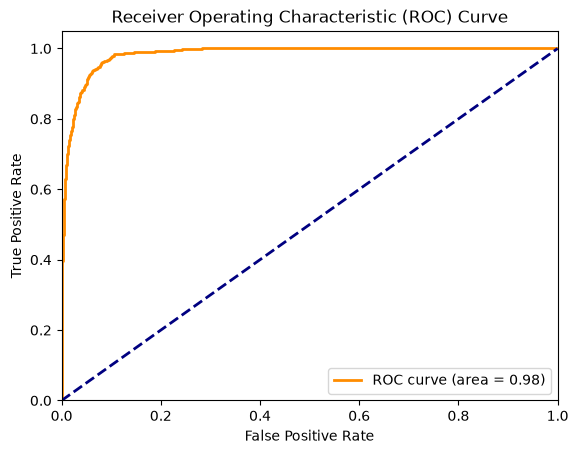

In [89]:
plt.figure()
plt.plot(fpr, tpr, color="darkorange", lw=2, label="ROC curve (area = %0.2f)" % area)
plt.plot([0,1], [0,1], color="navy", lw=2, linestyle="--")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()

In [90]:
probabilities = best_model_logistic.predict_proba(X_test_encoded)[:,1]

df_eval = pd.DataFrame({
    "Default Truth": y_test,
    "Default Probability": probabilities
})

df_eval.head(3)

,Default Truth,Default Probability
19205,0,0.532
15514,0,0.000
30367,0,0.006


#### Rank Ordering and KS Statistic

In [91]:
df_eval["Decile"] = pd.qcut(df_eval["Default Probability"], 10, labels = False, duplicates = "drop")
df_eval.head(3)

,Default Truth,Default Probability,Decile
19205,0,0.532,8
15514,0,0.000,2
30367,0,0.006,6


In [92]:
df_decile = df_eval.groupby('Decile').apply(lambda x: pd.Series({
    'Minimum Probability': x['Default Probability'].min(),
    'Maximum Probability': x['Default Probability'].max(),
    'Events': x['Default Truth'].sum(),
    'Non-events': x['Default Truth'].count() - x['Default Truth'].sum(),    
}))
df_decile.reset_index(inplace=True)
df_decile

,Decile,Minimum Probability,Maximum Probability,Events,Non-events
0,0,0.000,0.000,0.000,1250.000
1,1,0.000,0.000,0.000,1250.000
2,2,0.000,0.000,0.000,1249.000
3,3,0.000,0.000,0.000,1250.000
4,4,0.000,0.001,0.000,1250.000
5,5,0.001,0.004,0.000,1249.000
6,6,0.004,0.029,5.000,1245.000
7,7,0.029,0.213,11.000,1238.000
8,8,0.213,0.819,159.000,1091.000
9,9,0.820,1.000,899.000,351.000


In [93]:
df_decile['Event Rate'] = df_decile['Events']*100 / (df_decile['Events']+df_decile['Non-events'])
df_decile['Non-event Rate'] = df_decile['Non-events']*100 / (df_decile['Events']+df_decile['Non-events'])
df_decile

,Decile,Minimum Probability,Maximum Probability,Events,Non-events,Event Rate,Non-event Rate
0,0,0.000,0.000,0.000,1250.000,0.000,100.000
1,1,0.000,0.000,0.000,1250.000,0.000,100.000
2,2,0.000,0.000,0.000,1249.000,0.000,100.000
3,3,0.000,0.000,0.000,1250.000,0.000,100.000
4,4,0.000,0.001,0.000,1250.000,0.000,100.000
5,5,0.001,0.004,0.000,1249.000,0.000,100.000
6,6,0.004,0.029,5.000,1245.000,0.400,99.600
7,7,0.029,0.213,11.000,1238.000,0.881,99.119
8,8,0.213,0.819,159.000,1091.000,12.720,87.280
9,9,0.820,1.000,899.000,351.000,71.920,28.080


In [94]:
df_decile = df_decile.sort_values(by='Decile', ascending=False).reset_index(drop=True)
df_decile

,Decile,Minimum Probability,Maximum Probability,Events,Non-events,Event Rate,Non-event Rate
0,9,0.820,1.000,899.000,351.000,71.920,28.080
1,8,0.213,0.819,159.000,1091.000,12.720,87.280
2,7,0.029,0.213,11.000,1238.000,0.881,99.119
3,6,0.004,0.029,5.000,1245.000,0.400,99.600
4,5,0.001,0.004,0.000,1249.000,0.000,100.000
5,4,0.000,0.001,0.000,1250.000,0.000,100.000
6,3,0.000,0.000,0.000,1250.000,0.000,100.000
7,2,0.000,0.000,0.000,1249.000,0.000,100.000
8,1,0.000,0.000,0.000,1250.000,0.000,100.000
9,0,0.000,0.000,0.000,1250.000,0.000,100.000


In [95]:
df_decile['Cum Events'] =  df_decile['Events'].cumsum()
df_decile['Cum Non-events'] =  df_decile['Non-events'].cumsum()
df_decile

,Decile,Minimum Probability,Maximum Probability,Events,Non-events,Event Rate,Non-event Rate,Cum Events,Cum Non-events
0,9,0.820,1.000,899.000,351.000,71.920,28.080,899.000,351.000
1,8,0.213,0.819,159.000,1091.000,12.720,87.280,1058.000,1442.000
2,7,0.029,0.213,11.000,1238.000,0.881,99.119,1069.000,2680.000
3,6,0.004,0.029,5.000,1245.000,0.400,99.600,1074.000,3925.000
4,5,0.001,0.004,0.000,1249.000,0.000,100.000,1074.000,5174.000
5,4,0.000,0.001,0.000,1250.000,0.000,100.000,1074.000,6424.000
6,3,0.000,0.000,0.000,1250.000,0.000,100.000,1074.000,7674.000
7,2,0.000,0.000,0.000,1249.000,0.000,100.000,1074.000,8923.000
8,1,0.000,0.000,0.000,1250.000,0.000,100.000,1074.000,10173.000
9,0,0.000,0.000,0.000,1250.000,0.000,100.000,1074.000,11423.000


In [96]:
df_decile['Cum Event Rate'] = df_decile['Cum Events'] * 100 / df_decile['Events'].sum()
df_decile['Cum Non-event Rate'] = df_decile['Cum Non-events']*100 / df_decile['Non-events'].sum()
df_decile

,Decile,Minimum Probability,Maximum Probability,Events,Non-events,Event Rate,Non-event Rate,Cum Events,Cum Non-events,Cum Event Rate,Cum Non-event Rate
0,9,0.820,1.000,899.000,351.000,71.920,28.080,899.000,351.000,83.706,3.073
1,8,0.213,0.819,159.000,1091.000,12.720,87.280,1058.000,1442.000,98.510,12.624
2,7,0.029,0.213,11.000,1238.000,0.881,99.119,1069.000,2680.000,99.534,23.461
3,6,0.004,0.029,5.000,1245.000,0.400,99.600,1074.000,3925.000,100.000,34.361
4,5,0.001,0.004,0.000,1249.000,0.000,100.000,1074.000,5174.000,100.000,45.295
5,4,0.000,0.001,0.000,1250.000,0.000,100.000,1074.000,6424.000,100.000,56.237
6,3,0.000,0.000,0.000,1250.000,0.000,100.000,1074.000,7674.000,100.000,67.180
7,2,0.000,0.000,0.000,1249.000,0.000,100.000,1074.000,8923.000,100.000,78.114
8,1,0.000,0.000,0.000,1250.000,0.000,100.000,1074.000,10173.000,100.000,89.057
9,0,0.000,0.000,0.000,1250.000,0.000,100.000,1074.000,11423.000,100.000,100.000


In [97]:
df_decile["KS"] = abs(df_decile["Cum Event Rate"] - df_decile["Cum Non-event Rate"])
df_decile

,Decile,Minimum Probability,Maximum Probability,Events,Non-events,Event Rate,Non-event Rate,Cum Events,Cum Non-events,Cum Event Rate,Cum Non-event Rate,KS
0,9,0.820,1.000,899.000,351.000,71.920,28.080,899.000,351.000,83.706,3.073,80.633
1,8,0.213,0.819,159.000,1091.000,12.720,87.280,1058.000,1442.000,98.510,12.624,85.887
2,7,0.029,0.213,11.000,1238.000,0.881,99.119,1069.000,2680.000,99.534,23.461,76.073
3,6,0.004,0.029,5.000,1245.000,0.400,99.600,1074.000,3925.000,100.000,34.361,65.639
4,5,0.001,0.004,0.000,1249.000,0.000,100.000,1074.000,5174.000,100.000,45.295,54.705
5,4,0.000,0.001,0.000,1250.000,0.000,100.000,1074.000,6424.000,100.000,56.237,43.763
6,3,0.000,0.000,0.000,1250.000,0.000,100.000,1074.000,7674.000,100.000,67.180,32.820
7,2,0.000,0.000,0.000,1249.000,0.000,100.000,1074.000,8923.000,100.000,78.114,21.886
8,1,0.000,0.000,0.000,1250.000,0.000,100.000,1074.000,10173.000,100.000,89.057,10.943
9,0,0.000,0.000,0.000,1250.000,0.000,100.000,1074.000,11423.000,100.000,100.000,0.000


#### Rank Ordering

Rank ordering checks whether customers with higher predicted probabilities are concentrated in the higher deciles. A good rank ordering should show a generally decreasing event rate as we move from the highest-risk decile to the lowest-risk decile.

**Insights**

- Decile 9 has the highest event rate at **72.00%**, indicating that customers in this decile have the highest predicted risk of default.
- Decile 8 has an event rate of **12.72%**, and the cumulative event rate reaches **98.60%** by this decile.
- Event rates drop significantly in Deciles 7 and 6.
- Deciles 5 to 0 have **zero events**, with a 100% non-event rate.

#### KS Statistic

The KS statistic measures the maximum difference between the cumulative event rate and cumulative non-event rate.

**Insights**

- The highest KS value is **85.98% at Decile 8**, showing strong separation between events and non-events.
- The KS value decreases after Decile 8, meaning the difference between cumulative defaults and non-defaults becomes smaller.

#### AUC and Gini Coefficient

In [98]:
gini_coefficient = 2 * area - 1

print("AUC", area)
print("Gini Coefficient", gini_coefficient)

AUC 0.9836761436097677
Gini Coefficient 0.9673522872195355



- **AUC of 0.98:** The model has a strong ability to distinguish between default and non-default customers.

- **Gini coefficient of 0.96:** The Gini coefficient is derived from AUC using `Gini = 2 × AUC - 1`. It provides the same discrimination information on the Gini scale, which is commonly used in credit risk modelling.

#### Finalizing Model and Feature Importance

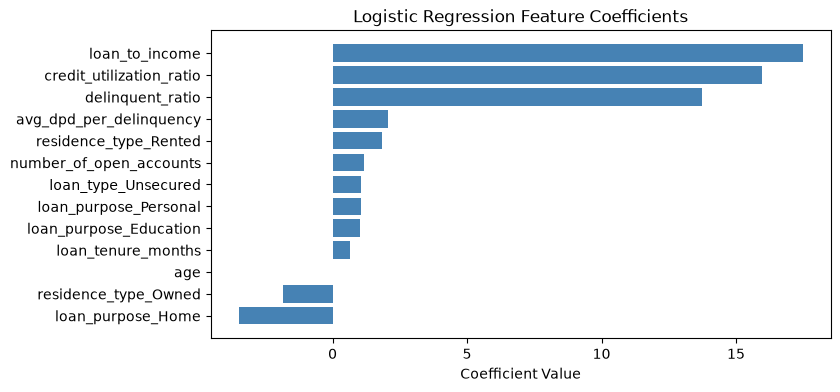

In [100]:
final_model = best_model_logistic

feature_importance = final_model.coef_[0]

coef_df = pd.DataFrame(feature_importance, index = X_train_encoded.columns, columns = ["Coefficient"])
coef_df = coef_df.sort_values(by="Coefficient", ascending = True)
coef_df

plt.figure(figsize = (8,4))
plt.barh(coef_df.index, coef_df["Coefficient"], color = "steelblue")
plt.xlabel('Coefficient Value')
plt.title('Logistic Regression Feature Coefficients')
plt.show()

#### Saving the Model

In [101]:
X_test_encoded.head(2)

,age,loan_tenure_months,number_of_open_accounts,credit_utilization_ratio,loan_to_income,delinquent_ratio,avg_dpd_per_delinquency,residence_type_Owned,residence_type_Rented,loan_purpose_Education,loan_purpose_Home,loan_purpose_Personal,loan_type_Unsecured
19205,0.346,0.755,0.333,0.990,0.550,0.000,0.000,True,False,False,True,False,False
15514,0.481,0.226,1.000,0.323,0.220,0.000,0.000,True,False,True,False,False,False


In [102]:
X_test_encoded.columns

Index(['age', 'loan_tenure_months', 'number_of_open_accounts',
       'credit_utilization_ratio', 'loan_to_income', 'delinquent_ratio',
       'avg_dpd_per_delinquency', 'residence_type_Owned',
       'residence_type_Rented', 'loan_purpose_Education', 'loan_purpose_Home',
       'loan_purpose_Personal', 'loan_type_Unsecured'],
      dtype='str')

In [103]:
X_train_encoded.columns

Index(['age', 'loan_tenure_months', 'number_of_open_accounts',
       'credit_utilization_ratio', 'loan_to_income', 'delinquent_ratio',
       'avg_dpd_per_delinquency', 'residence_type_Owned',
       'residence_type_Rented', 'loan_purpose_Education', 'loan_purpose_Home',
       'loan_purpose_Personal', 'loan_type_Unsecured'],
      dtype='str')

In [104]:
cols_to_scale

Index(['age', 'number_of_dependants', 'years_at_current_address', 'zipcode',
       'sanction_amount', 'processing_fee', 'gst', 'net_disbursement',
       'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'number_of_open_accounts',
       'number_of_closed_accounts', 'enquiry_count',
       'credit_utilization_ratio', 'loan_to_income', 'delinquent_ratio',
       'avg_dpd_per_delinquency'],
      dtype='str')

In [105]:
from joblib import dump

model_data = {
    'model': final_model,
    'features': X_train_encoded.columns,
    'scaler': scaler,
    'cols_to_scale': cols_to_scale
}
dump(model_data, 'artifacts/model_data.joblib')

['artifacts/model_data.joblib']

In [106]:
final_model.coef_, final_model.intercept_

(array([[ 0.00140625,  0.63436204,  1.18091   , 15.9530341 , 17.47258036,
         13.73703006,  2.04803704, -1.84116756,  1.85195417,  1.00272081,
         -3.48271779,  1.06076549,  1.06076549]]),
 array([-20.82833935]))